# Acquisition Function Output Analysis: Multiscale and Single Scale

Load saved active-learning results and compare random acquisition with the distance acquisition function ($\beta=1$). The initial analysis uses the multiscale result by default.

In [4]:
%matplotlib inline

from pathlib import Path
import re

import h5py
import numpy as np
import matplotlib.pyplot as plt


cwd = Path.cwd()
stm_dir = cwd / "notebooks" / "STM" if (cwd / "notebooks" / "STM").exists() else cwd
results_dir = stm_dir / "data" / "active_learning_results1"

error_type = "L1"  # "L1", "L2", or "cos"_
acquisition_iterations = 50
num_new_points = 5
default_scale_type = "ms"
norm_type = "normgauss"

# The initial cells analyze the multiscale distance-acquisition run.
output_file = results_dir / (
    f"al_im2spec_{error_type}_WS32_latent5_appendpad_"
    f"{acquisition_iterations}iters_{num_new_points}pts_"
    f"distanceacq_{default_scale_type}_{norm_type}_mask.h5"
)
output_file

PosixPath('/home/cloud/nfs_share/vm_dir/NN_Error/notebooks/STM/data/active_learning_results1/al_im2spec_L1_WS32_latent5_appendpad_50iters_5pts_distanceacq_ms_normgauss_mask.h5')

In [5]:
def plot_reduced_errors_and_scales(errors, coords_reduced, aq_indices=None):
    xs = coords_reduced[:, 0]
    ys = coords_reduced[:, 1]
    scales = coords_reduced[:, 2]

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    sc0 = axes[0].scatter(xs, ys, c=errors, s=80)
    axes[0].set_title("Reduced Minimum Errors, mean = {:.3f}".format(np.mean(errors)))
    axes[0].set_xlabel("x")
    axes[0].set_ylabel("y")
    axes[0].set_aspect("equal")
    plt.colorbar(sc0, ax=axes[0], label="Minimum Error")

    sc1 = axes[1].scatter(xs, ys, c=scales, s=80)
    axes[1].set_title("Best Scale at Each (x, y)")
    axes[1].set_xlabel("x")
    axes[1].set_ylabel("y")
    axes[1].set_aspect("equal")
    plt.colorbar(sc1, ax=axes[1], label="Best Scale")

    if aq_indices is not None and len(aq_indices) > 0:
        aq_indices = np.asarray(aq_indices, dtype=int)
        axes[0].scatter(
            xs[aq_indices],
            ys[aq_indices],
            marker="x",
            s=120,
            linewidths=2,
            label="Acquisition points",
        )
        axes[0].legend()

    plt.tight_layout()
    plt.show()


def load_h5_ragged(filename):
    data_dict = {}
    with h5py.File(filename, "r") as f:
        for key in f.keys():
            group = f[key]
            data_dict[key] = [group[str(i)][()] for i in range(len(group))]
    return data_dict


def infer_num_new_points(output_dict, output_file, fallback=5):
    match = re.search(r"_(\d+)pts_", output_file.name)
    if match:
        return int(match.group(1))

    train_indices = output_dict.get("train_indices", [])
    if len(train_indices) > 1:
        return int(len(train_indices[1]) - len(train_indices[0]))

    return fallback


def build_result_file(model_type, append_mode, acquisition, scale_type, norm_type):
    return results_dir / (
        f"al_{model_type}_{error_type}_WS32_latent5_{append_mode}_"
        f"{acquisition_iterations}iters_{num_new_points}pts_"
        f"{acquisition}acq_{scale_type}_{norm_type}{'_mask' if scale_type == 'ms' else ''}.h5"
    )

In [6]:
output_dict = load_h5_ragged(output_file)
{key: len(value) for key, value in output_dict.items()}

{'im2spec_test_mismatches': 50,
 'pred_error_test': 50,
 'predicted_errors_all': 50,
 'reduced_coords': 50,
 'reduced_errors': 50,
 'reduced_errors_im2spec': 50,
 'test_indices': 50,
 'train_indices': 50}

(347,)
Acquired points: 245


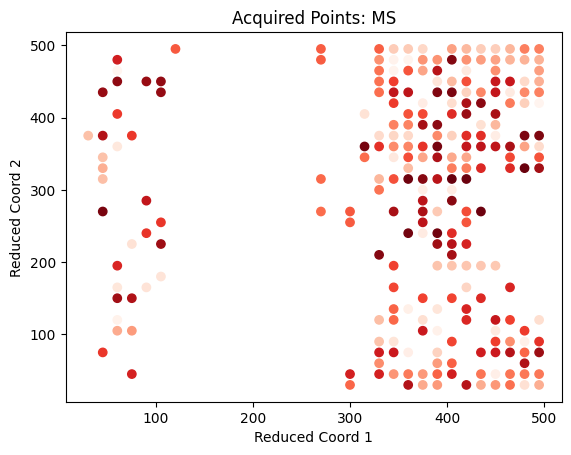

In [7]:
train_indices = output_dict.get("train_indices")

acquired_indices = [ind for ind in train_indices[-1] if ind not in train_indices[0]]
acquired_indices = np.asarray(acquired_indices, dtype=int)
acq_coords = output_dict["reduced_coords"][-1][acquired_indices]

print(train_indices[-1].shape)
print(f"Acquired points: {len(acquired_indices)}")

fig, ax = plt.subplots()
ax.scatter(
    acq_coords[:, 0],
    acq_coords[:, 1],
    c=np.arange(len(acq_coords)),
    cmap="Reds",
    marker="o",
)
ax.set_xlabel("Reduced Coord 1")
ax.set_ylabel("Reduced Coord 2")
ax.set_title(f"Acquired Points: {default_scale_type.upper()}")
plt.show()

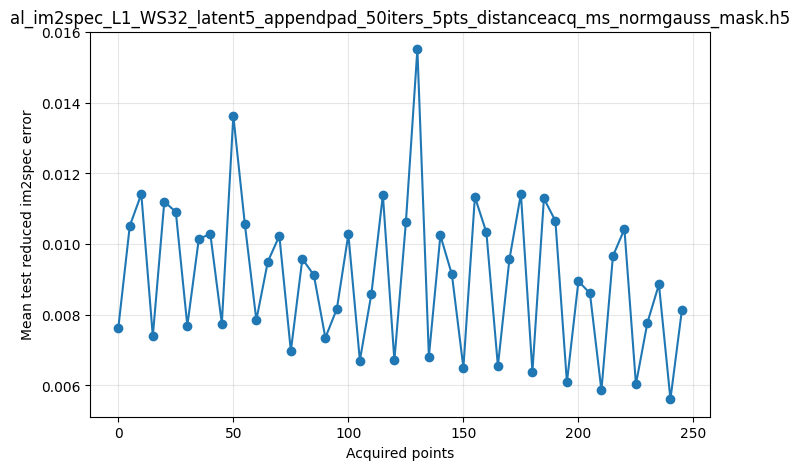

In [8]:
train_indices_arr = output_dict["train_indices"]
test_indices_arr = [indices.astype(int) for indices in output_dict["test_indices"]]
reduced_errors_arr = np.array(output_dict["reduced_errors_im2spec"])

num_saved_iterations = len(reduced_errors_arr)
points_per_iteration = infer_num_new_points(output_dict, output_file)
test_reduced_errors = [
    reduced_errors_arr[i][test_indices_arr[i]]
    for i in range(num_saved_iterations)
]
mean_test_reduced_errors = [np.mean(errors) for errors in test_reduced_errors]

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(
    np.arange(num_saved_iterations) * points_per_iteration,
    mean_test_reduced_errors,
    marker="o",
)
ax.set_xlabel("Acquired points")
ax.set_ylabel("Mean test reduced im2spec error")
ax.set_title(Path(output_file).name)
ax.grid(True, alpha=0.3)
plt.show()

Plotting iteration -50 from al_im2spec_L1_WS32_latent5_appendpad_50iters_5pts_distanceacq_ms_normgauss_mask.h5


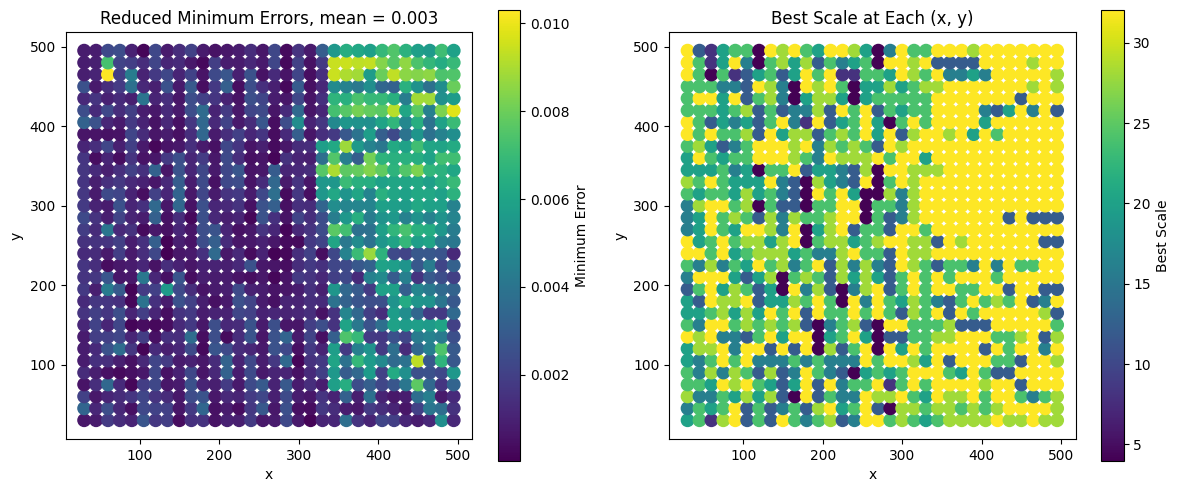

In [16]:
plot_iteration = -50
error_key = "reduced_errors"

if "reduced_coords" not in output_dict:
    raise KeyError(
        "This output file does not contain reduced_coords. "
        "Re-run stm_ms_acqfn_script.py after the reduced_coords save change."
    )

reduced_errors_to_plot = np.asarray(output_dict[error_key][plot_iteration])
reduced_coords_to_plot = np.asarray(output_dict["reduced_coords"][plot_iteration])

print(f"Plotting iteration {plot_iteration} from {Path(output_file).name}")
plot_reduced_errors_and_scales(reduced_errors_to_plot, reduced_coords_to_plot)

## Compare random and distance acquisition by scale type

Multiscale (`ms`) and single-scale (`ss`) results are displayed in separate figures. Random acquisition is blue; distance acquisition ($\beta=1$) is orange.

In [10]:
def calculate_mean_test_reduced_im2spec_error(output_dict):
    reduced_errors = output_dict["reduced_errors_im2spec"]
    test_indices = output_dict["test_indices"]

    if len(reduced_errors) != len(test_indices):
        raise ValueError(
            "reduced_errors_im2spec and test_indices have different iteration counts"
        )

    return np.asarray([
        np.mean(np.asarray(errors)[np.asarray(indices, dtype=int)])
        for errors, indices in zip(reduced_errors, test_indices)
    ])


model_configs = {
    "im2spec": "appendpad",
}
scale_labels = {
    "ms": "Multiscale (MS)",
    "ss": "Single scale (SS)",
}
acquisition_colors = {
    "random": "tab:blue",
    "distance": "tab:orange",
}
acquisition_labels = {
    "random": "Random",
    "distance": "Acquisition function ($\\beta=1$)",
}

comparison_results = {}

for scale_type in ("ms", "ss"):
    comparison_results[scale_type] = {}
    for model_type, append_mode in model_configs.items():
        comparison_results[scale_type][model_type] = {}

        for acquisition in ("random", "distance"):
            result_file = build_result_file(
                model_type,
                append_mode,
                acquisition,
                scale_type,
                norm_type,
            )
            if not result_file.exists():
                raise FileNotFoundError(result_file)

            result_dict = load_h5_ragged(result_file)
            mean_errors = calculate_mean_test_reduced_im2spec_error(result_dict)
            points_per_iteration = infer_num_new_points(result_dict, result_file)

            comparison_results[scale_type][model_type][acquisition] = {
                "output_file": result_file,
                "output_dict": result_dict,
                "acquired_points": np.arange(len(mean_errors)) * points_per_iteration,
                "mean_test_reduced_im2spec_error": mean_errors,
            }

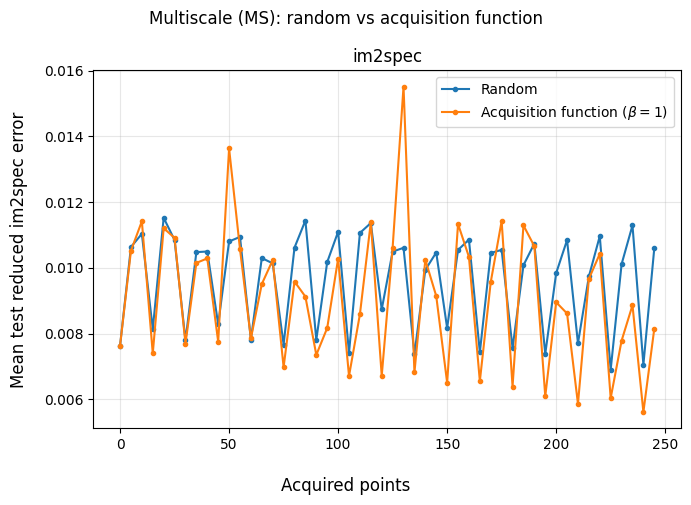

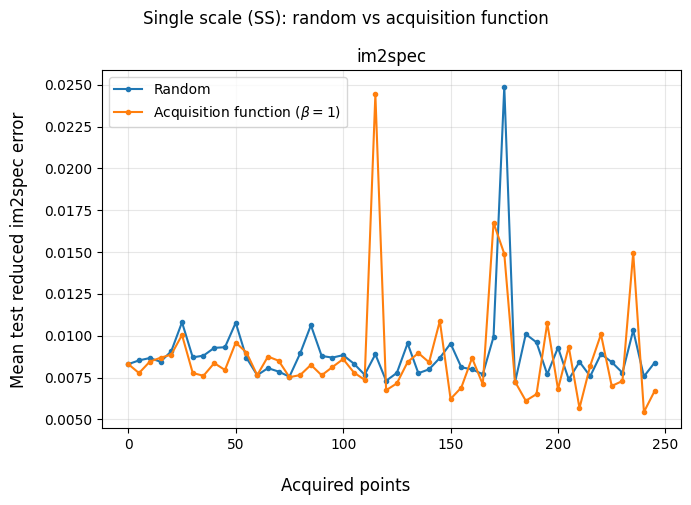

In [11]:
# Mean test-error series: one figure for MS and one figure for SS.
for scale_type in ("ms", "ss"):
    fig, axes = plt.subplots(
        1,
        len(model_configs),
        figsize=(7 * len(model_configs), 5),
        squeeze=False,
        sharex=True,
        sharey=True,
    )

    for ax, (model_type, acquisition_results) in zip(
        axes.flat,
        comparison_results[scale_type].items(),
    ):
        for acquisition in ("random", "distance"):
            result = acquisition_results[acquisition]
            ax.plot(
                result["acquired_points"],
                result["mean_test_reduced_im2spec_error"],
                color=acquisition_colors[acquisition],
                marker="o",
                markersize=3,
                label=acquisition_labels[acquisition],
            )

        ax.set_title(model_type)
        ax.grid(True, alpha=0.3)
        ax.legend()

    fig.supxlabel("Acquired points")
    fig.supylabel("Mean test reduced im2spec error")
    fig.suptitle(f"{scale_labels[scale_type]}: random vs acquisition function")
    fig.tight_layout()
    plt.show()

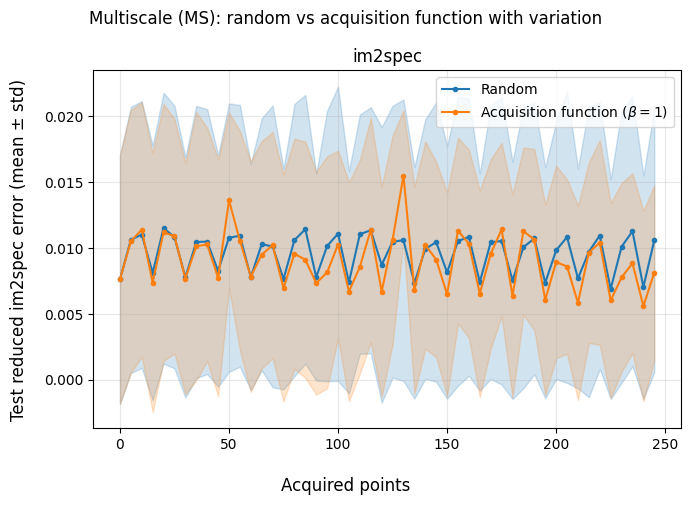

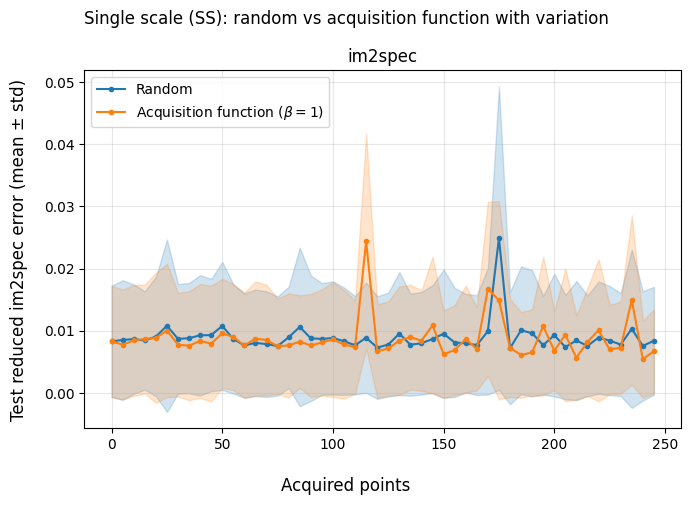

In [12]:
# Mean ± standard-deviation series: one figure for MS and one figure for SS.
for scale_type in ("ms", "ss"):
    fig, axes = plt.subplots(
        1,
        len(model_configs),
        figsize=(7 * len(model_configs), 5),
        squeeze=False,
        sharex=True,
        sharey=True,
    )

    for ax, (model_type, acquisition_results) in zip(
        axes.flat,
        comparison_results[scale_type].items(),
    ):
        for acquisition in ("random", "distance"):
            result = acquisition_results[acquisition]
            result_dict = result["output_dict"]
            test_errors = [
                np.asarray(errors)[np.asarray(indices, dtype=int)]
                for errors, indices in zip(
                    result_dict["reduced_errors_im2spec"],
                    result_dict["test_indices"],
                )
            ]
            std_errors = np.asarray([np.std(errors) for errors in test_errors])
            mean_errors = result["mean_test_reduced_im2spec_error"]
            acquired_points = result["acquired_points"]

            ax.plot(
                acquired_points,
                mean_errors,
                color=acquisition_colors[acquisition],
                marker="o",
                markersize=3,
                label=acquisition_labels[acquisition],
            )
            ax.fill_between(
                acquired_points,
                mean_errors - std_errors,
                mean_errors + std_errors,
                color=acquisition_colors[acquisition],
                alpha=0.2,
            )

        ax.set_title(model_type)
        ax.grid(True, alpha=0.3)
        ax.legend()

    fig.supxlabel("Acquired points")
    fig.supylabel("Test reduced im2spec error (mean ± std)")
    fig.suptitle(
        f"{scale_labels[scale_type]}: random vs acquisition function with variation"
    )
    fig.tight_layout()
    plt.show()

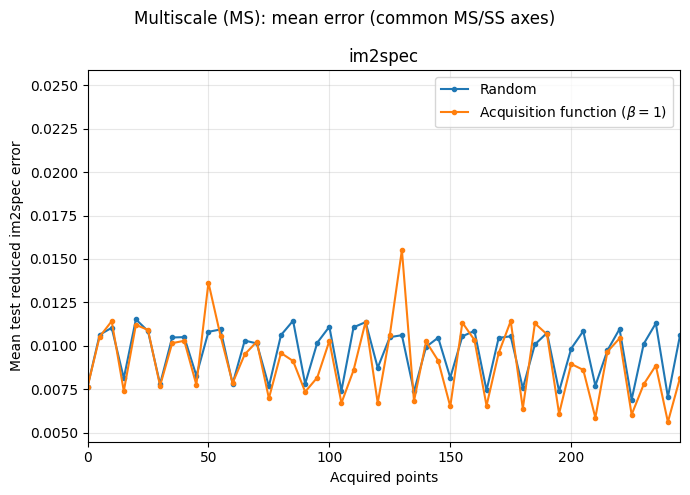

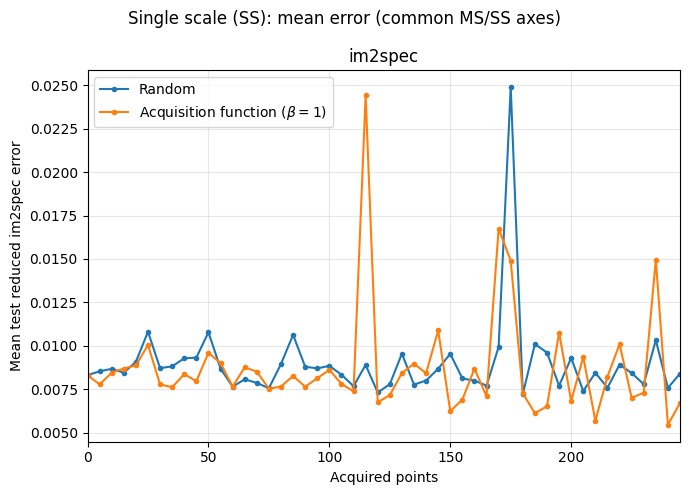

In [13]:
# Mean-only figures with common axis limits for direct MS/SS comparison.
all_acquired_points = []
all_mean_errors = []

for scale_type in ("ms", "ss"):
    for acquisition_results in comparison_results[scale_type].values():
        for acquisition in ("random", "distance"):
            result = acquisition_results[acquisition]
            all_acquired_points.append(np.asarray(result["acquired_points"]))
            all_mean_errors.append(
                np.asarray(result["mean_test_reduced_im2spec_error"])
            )

all_acquired_points = np.concatenate(all_acquired_points)
all_mean_errors = np.concatenate(all_mean_errors)

common_xlim = (all_acquired_points.min(), all_acquired_points.max())
error_min = all_mean_errors.min()
error_max = all_mean_errors.max()
error_span = error_max - error_min
error_padding = 0.05 * error_span if error_span > 0 else 0.05
common_ylim = (error_min - error_padding, error_max + error_padding)

for scale_type in ("ms", "ss"):
    fig, axes = plt.subplots(
        1,
        len(model_configs),
        figsize=(7 * len(model_configs), 5),
        squeeze=False,
    )

    for ax, (model_type, acquisition_results) in zip(
        axes.flat,
        comparison_results[scale_type].items(),
    ):
        for acquisition in ("random", "distance"):
            result = acquisition_results[acquisition]
            ax.plot(
                result["acquired_points"],
                result["mean_test_reduced_im2spec_error"],
                color=acquisition_colors[acquisition],
                marker="o",
                markersize=3,
                label=acquisition_labels[acquisition],
            )

        ax.set_xlim(common_xlim)
        ax.set_ylim(common_ylim)
        ax.set_title(model_type)
        ax.set_xlabel("Acquired points")
        ax.set_ylabel("Mean test reduced im2spec error")
        ax.grid(True, alpha=0.3)
        ax.legend()

    fig.suptitle(
        f"{scale_labels[scale_type]}: mean error (common MS/SS axes)"
    )
    fig.tight_layout()
    plt.show()